# IL-8 (CXCL8) across infection contexts vs butyrate dose — overplot

**Question:** how does *butyrate alone, at each dose* compare to the different *infection
contexts* for the inflammatory decision point IL-8 (CXCL8)?

**LFC extraction reuses the co-infection figure's method** (`Epithelial_Coinfection_LFC_Correlation`):
the A06 log2FC/padj come from the wide feature matrix `analysis/causal_v6/full_feature_matrix.csv`
(`feat_df`, columns `lfc_Bt/Cd/Co`, `padj_Bt/Cd/Co`) via the same `get_lfc_padj(gene, condition)`
pattern. The A04 butyrate conditions come from the DE tables. One gene, all conditions, overplotted.

Kernel: any pandas/matplotlib env.

In [1]:
import pandas as pd, numpy as np, re, os, glob
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch

A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'axes.linewidth':0.8,'axes.edgecolor':'#444','axes.spines.top':False,'axes.spines.right':False,
  'xtick.color':'#444','ytick.color':'#444','text.color':'#222','axes.labelcolor':'#222',
  'figure.dpi':140,'savefig.dpi':300,'savefig.bbox':'tight'})

GENE = 'CXCL8'   # IL-8

## 1. A06 conditions — exact method from the correlation figure (feat_df wide matrix)

In [2]:
# same source + fallbacks as Epithelial_Coinfection_LFC_Correlation
feat_path=None
for p in ['analysis/causal_v6/full_feature_matrix.csv',
          'analysis/causal_v4/full_feature_matrix.csv',
          'analysis/causal_v2/full_feature_matrix.csv',
          'analysis/network_diffusion/full_feature_matrix.csv']:
    if (A06/p).exists(): feat_path=A06/p; break
print('feat_df:', feat_path)
feat_df=pd.read_csv(feat_path, index_col='gene')
print('shape',feat_df.shape,'| lfc cols:',[c2 for c2 in feat_df.columns if c2.startswith('lfc_')])

def get_lfc_padj(gene, cond):
    if gene not in feat_df.index: return (0.0,1.0)
    r=feat_df.loc[gene]
    return float(r.get(f'lfc_{cond}',0.0)), float(r.get(f'padj_{cond}',1.0))

# A06 conditions (all vs Mock): Bt, Cd, Co
A06_conds=[('Cd','Cd vs Mock'),('Co','Co-infection vs Mock'),('Bt','Bt vs Mock')]
rows=[]
for cond,label in A06_conds:
    lfc,padj=get_lfc_padj(GENE,cond)
    rows.append(dict(label=label,group='infection context',lfc=lfc,padj=padj))
print('A06 rows:'); [print('  ',r) for r in rows]

feat_df: /home/job37yv/Projects_shared/epithelial_coinfection-model_WORKING/analysis/causal_v6/full_feature_matrix.csv
shape (766, 43) | lfc cols: ['lfc_Bt', 'lfc_Cd', 'lfc_Co', 'lfc_Bt_vs_Cd', 'lfc_Co_vs_Cd']
A06 rows:
   {'label': 'Cd vs Mock', 'group': 'infection context', 'lfc': 3.1974673323878995, 'padj': 3.139687571933449e-09}
   {'label': 'Co-infection vs Mock', 'group': 'infection context', 'lfc': 0.877123883466511, 'padj': 0.4466157369229117}
   {'label': 'Bt vs Mock', 'group': 'infection context', 'lfc': 0.1558467186220576, 'padj': 0.9791121804294538}


[None, None, None]

## 2. A04 conditions — butyrate at each dose/context (DE tables)

In [3]:
def load_de(fname):
    f=A04/'results/tables'/fname
    if not f.exists(): print('  MISSING',fname); return None
    d=pd.read_csv(f,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    return d
def de_val(fname,gene):
    d=load_de(fname)
    if d is None or gene not in d.index: return (np.nan,np.nan)
    r=d.loc[gene]; return float(r.get('log2FoldChange',np.nan)), float(r.get('padj',np.nan))

A04_conds=[
  ('DE_Butyrate_5v0_Mock.csv', 'Butyrate 5mM (Mock)',  'butyrate only'),
  ('DE_Butyrate_10v0_Mock.csv','Butyrate 10mM (Mock)', 'butyrate only'),
  ('DE_Butyrate_5v0_Cd.csv',   'Butyrate 5mM (in Cd)', 'butyrate + infection'),
  ('DE_Butyrate_10v0_Cd.csv',  'Butyrate 10mM (in Cd)','butyrate + infection'),
  ('DE_Cd_vs_Mock_0mM.csv',    'Cd vs Mock (0mM)',     'infection context'),
  ('DE_Cd_vs_Mock_5mM.csv',    'Cd vs Mock (5mM)',     'infection context'),
  ('DE_Cd_vs_Mock_10mM.csv',   'Cd vs Mock (10mM)',    'infection context'),
]
for fn,label,grp in A04_conds:
    lfc,padj=de_val(fn,GENE)
    if not np.isnan(lfc): rows.append(dict(label=label,group=grp,lfc=lfc,padj=padj))
df=pd.DataFrame(rows)
print('\nAll conditions for',GENE,':'); print(df.round(3).to_string())


All conditions for CXCL8 :
                   label                 group    lfc   padj
0             Cd vs Mock     infection context  3.197  0.000
1   Co-infection vs Mock     infection context  0.877  0.447
2             Bt vs Mock     infection context  0.156  0.979
3    Butyrate 5mM (Mock)         butyrate only -0.922  0.080
4   Butyrate 10mM (Mock)         butyrate only -1.544  0.000
5   Butyrate 5mM (in Cd)  butyrate + infection -0.925  0.034
6  Butyrate 10mM (in Cd)  butyrate + infection -3.734  0.000
7       Cd vs Mock (0mM)     infection context  4.090  0.000
8       Cd vs Mock (5mM)     infection context  4.086  0.000
9      Cd vs Mock (10mM)     infection context  1.900  0.000


## 3. Overplot — IL-8 log2FC across every condition, grouped, p-value encoded

/tmp/ipykernel_2261136/1876798507.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bounds=df.groupby('go').apply(lambda d: (d.index.min(),d.index.max()))


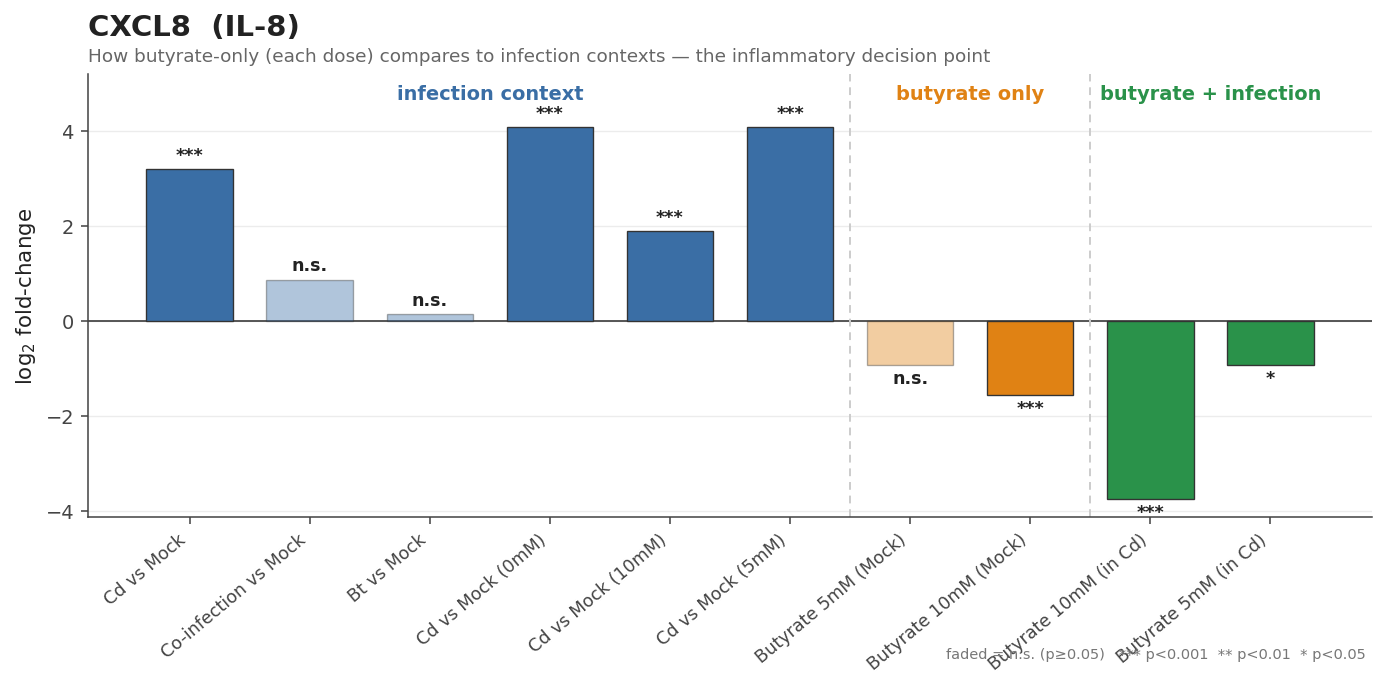

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/CXCL8_butyrate_vs_infection_contexts.png


In [4]:
def stars(p):
    if pd.isna(p): return 'n.s.'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'n.s.'

# group order + colours: infection context (blue), butyrate only (orange), butyrate+infection (green)
group_order=['infection context','butyrate only','butyrate + infection']
gcol={'infection context':'#3a6ea5','butyrate only':'#e08214','butyrate + infection':'#2a924a'}
df['go']=df.group.map({g:i for i,g in enumerate(group_order)})
df=df.sort_values(['go']).reset_index(drop=True)

n=len(df); x=np.arange(n)
alphas=[1.0 if (not pd.isna(p) and p<0.05) else 0.4 for p in df.padj]
colors=[gcol[g] for g in df.group]

fig,ax=plt.subplots(figsize=(max(8,0.8*n+2),5.2))
bars=ax.bar(x,df.lfc,color=colors,edgecolor='#333',lw=.7,width=.72,zorder=3)
for b,a in zip(bars,alphas): b.set_alpha(a)
for xi,(_,r) in zip(x,df.iterrows()):
    ax.text(xi, r.lfc+(0.1 if r.lfc>=0 else -0.1), stars(r.padj),
            ha='center', va='bottom' if r.lfc>=0 else 'top', fontsize=9, fontweight='bold')
ax.axhline(0,color='#444',lw=.9)
# group dividers + headers
ylo,yhi=ax.get_ylim(); ax.set_ylim(ylo,yhi*1.16)
bounds=df.groupby('go').apply(lambda d: (d.index.min(),d.index.max()))
for gi,g in enumerate(group_order):
    sub=df[df.group==g]
    if len(sub)==0: continue
    lo,hi=sub.index.min(),sub.index.max()
    if hi<n-1: ax.axvline(hi+0.5,color='#ccc',ls=(0,(4,3)),lw=1)
    ax.text((lo+hi)/2, ax.get_ylim()[1]*0.96, g, ha='center', va='top',
            fontsize=10, color=gcol[g], fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(df.label,rotation=40,ha='right',fontsize=9)
ax.set_ylabel('log$_2$ fold-change',fontsize=11)
ax.set_title('CXCL8  (IL-8)',fontsize=15,fontweight='bold',loc='left',pad=20)
ax.text(0,1.03,'How butyrate-only (each dose) compares to infection contexts — the inflammatory decision point',
        transform=ax.transAxes,fontsize=9.5,color='#666')
ax.grid(axis='y',color='#ececec',lw=.7,zorder=0)
ax.text(0.995,-0.32,'faded = n.s. (p≥0.05)   *** p<0.001  ** p<0.01  * p<0.05',
        transform=ax.transAxes,ha='right',fontsize=7.5,color='#777')
plt.tight_layout(); fig.savefig(FIG/'CXCL8_butyrate_vs_infection_contexts.png'); plt.show()
print('wrote',FIG/'CXCL8_butyrate_vs_infection_contexts.png')

## 4. Reading it
- **infection context** (blue): CXCL8 induction by Cd (A06 Cd, and A04 Cd-vs-Mock at each dose),
  co-infection (A06 Co = attenuated), Bt alone.
- **butyrate only** (orange): butyrate in Mock — does the metabolite alone move IL-8 without infection?
- **butyrate + infection** (green): butyrate within Cd — the dose-dependent suppression (the −3.7 bar).

The comparison you asked for: line up the **butyrate-only** bars against the **co-infection (Co)** bar.
If butyrate-only lowers IL-8 similarly to how co-infection attenuates it, that supports "butyrate
reproduces the commensal's anti-inflammatory effect". Direction + significance are both shown.

To swap gene: set `GENE='...'` in cell 1 (e.g. HSPA5, CXCL1, CCL20) and re-run.